    # Concise Temperature Forecasting Project

Predict temperature six hours ahead from 24 hourly observations. Run each step and commit after successful execution.

Data Source: [MPI-BGC Beutenberg](https://weather.bgc-jena.mpg.de/weather_data.html), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

# 1. Environment and Setup
Fix model settings and create result folders.


In [1]:
import os
import tempfile
from pathlib import Path

# Keep Windows temporary files in the project.
Path(".runtime").mkdir(exist_ok=True)
tempfile.tempdir = str(Path(".runtime").resolve())
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_NUM_INTRAOP_THREADS"] = "4"
os.environ["TF_NUM_INTEROP_THREADS"] = "2"

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
import truststore
truststore.inject_into_ssl()
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

SEED, LOOKBACK, HORIZON = 504, 24, 6
FEATURES = ["T (degC)", "p (mbar)", "rh (%)", "wv (m/s)"]
for folder in ["data", "outputs", "models", "figures"]:
    Path(folder).mkdir(exist_ok=True)
tf.config.experimental.enable_op_determinism()
CONFIG = {"seed": SEED, "lookback": LOOKBACK, "horizon": HORIZON,
          "features": FEATURES, "learning_rate": 0.001, "batch_size": 64,
          "max_epochs": 30, "patience": 5}
Path("outputs/config.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")
print("Runtime versions:", keras.__version__, tf.__version__)

Runtime versions: 3.15.1 2.21.0


# 2. Download and clean
Source: MPI-BGC Beutenberg, CC BY 4.0. Check duplicate conflicts and mask invalid values.

In [2]:
from urllib.request import urlretrieve
from zipfile import ZipFile

names = [f"mpi_roof_{year}{half}" for year in range(2018, 2024) for half in "ab"]
names += ["mpi_roof_2024", "mpi_roof_2025"]
parts = []
for name in names:
    path = Path("data") / f"{name}.zip"
    if not path.exists():
        urlretrieve(f"https://www.bgc-jena.mpg.de/wetter/data/{name}.zip", path)
    with ZipFile(path) as archive:
        with archive.open(f"{name}.csv") as file:
            parts.append(pd.read_csv(file, encoding="latin-1"))

data = pd.concat(parts, ignore_index=True)
data["Date Time"] = pd.to_datetime(data["Date Time"], format="%d.%m.%Y %H:%M:%S")
# Resolve conflicting measurements before deduplication.
repeated = data[data["Date Time"].duplicated(keep=False)]
measurements = data.columns.drop("Date Time")
assert not repeated.groupby("Date Time")[measurements].nunique(dropna=False).gt(1).any().any()
observed = (data.sort_values("Date Time").drop_duplicates("Date Time")
            .set_index("Date Time")[FEATURES].copy())
observed = observed.replace([-9999, np.inf, -np.inf], np.nan)
observed.loc[observed["p (mbar)"] <= 0, "p (mbar)"] = np.nan
observed.loc[~observed["rh (%)"].between(0, 100), "rh (%)"] = np.nan
observed.loc[observed["wv (m/s)"] < 0, "wv (m/s)"] = np.nan
print("Raw/deduplicated rows:", len(data), len(observed))
display(observed.isna().sum().to_frame("Missing count"))

Raw/deduplicated rows: 420782 420631


,Missing count
T (degC),0
p (mbar),0
rh (%),0
wv (m/s),1


# 3. Continuous hourly data

Exact-hour values summarize the preceding ten minutes; retain missing hours without filling. Keep station clock labels.

In [3]:
# Select exact timestamps rather than every sixth row.
hourly_index = pd.date_range(observed.index.min().ceil("h"), observed.index.max().floor("h"), freq="h")
hourly = observed.reindex(hourly_index)
hourly.index.name = "Date Time"
hourly.to_csv("outputs/hourly_observations.csv")
print("Hourly slots/missing hours:", len(hourly), hourly.isna().all(axis=1).sum())

Hourly slots/missing hours: 70128 22


# 4. 归一化、窗口与划分 / Scaling, windows and splits

Inputs t-23h..t, target t+6h; split by target year with a shared four-feature mask.

In [4]:
# Fit on training hours only; keep targets in Celsius.
train_hours = hourly.loc[(hourly.index.year >= 2018) & (hourly.index.year <= 2023)]
mean, std = train_hours.mean(), train_hours.std(ddof=0)
assert np.isfinite(std).all() and (std > 0).all()
scaler = {"features": FEATURES, "means": mean.to_dict(), "stds": std.to_dict()}
Path("outputs/training_scaler.json").write_text(json.dumps(scaler, indent=2), encoding="utf-8")
scaled = ((hourly - mean) / std).to_numpy(dtype=np.float32)

ends = np.arange(LOOKBACK - 1, len(hourly) - HORIZON)
X = np.stack([scaled[t - LOOKBACK + 1:t + 1] for t in ends])
y = hourly[FEATURES[0]].to_numpy()[ends + HORIZON].astype(np.float32)
latest = hourly[FEATURES[0]].to_numpy()[ends].astype(np.float32)
targets = hourly.index[ends + HORIZON]
# Check inputs/targets, not unused t+1..t+5.
valid = np.isfinite(X).all(axis=(1, 2)) & np.isfinite(y)
splits = {}
for name, years in {"train": (2018, 2023), "val": (2024, 2024), "test": (2025, 2025)}.items():
    keep = valid & (targets.year >= years[0]) & (targets.year <= years[1])
    splits[name] = {"X": X[keep], "y": y[keep], "latest": latest[keep], "times": targets[keep]}
assert (targets - hourly.index[ends] == pd.Timedelta(hours=HORIZON)).all()
display(pd.DataFrame({name: {"Samples": len(part["y"])} for name, part in splits.items()}).T)

,Samples
train,52449
val,8784
test,8760


# 5. Persistence validation baseline

Evaluate validation first; test after all models are trained.

In [5]:
def metrics(y, prediction):
    """Errors in degrees Celsius."""
    error = np.asarray(prediction, dtype=float) - np.asarray(y, dtype=float)
    return {"samples": len(error), "mae_c": float(np.abs(error).mean()),
            "rmse_c": float(np.sqrt(np.square(error).mean())), "bias_c": float(error.mean())}

baseline = metrics(splits["val"]["y"], splits["val"]["latest"])
pd.DataFrame([baseline], index=["persistence"]).to_csv("outputs/baseline_validation.csv")
print("Persistence validation:", baseline)

Persistence validation: {'samples': 8784, 'mae_c': 3.3267588744085037, 'rmse_c': 4.36269431262839, 'bias_c': 0.00519922586498894}


# 6. Temperature Dense and training helper

Apply the same plan to all models; restore the best validation-MSE weights.

Epoch 1/30
820/820 - 1s - 1ms/step - loss: 41.6864 - mae: 4.9066 - val_loss: 14.0104 - val_mae: 2.9726
Epoch 2/30
820/820 - 1s - 662us/step - loss: 8.8482 - mae: 2.2855 - val_loss: 6.9169 - val_mae: 2.0437
Epoch 3/30
820/820 - 1s - 613us/step - loss: 6.7124 - mae: 1.9673 - val_loss: 6.2975 - val_mae: 1.9396
Epoch 4/30
820/820 - 1s - 639us/step - loss: 6.2320 - mae: 1.8903 - val_loss: 5.9852 - val_mae: 1.8908
Epoch 5/30
820/820 - 1s - 655us/step - loss: 6.0559 - mae: 1.8633 - val_loss: 5.8306 - val_mae: 1.8622
Epoch 6/30
820/820 - 1s - 634us/step - loss: 5.9567 - mae: 1.8480 - val_loss: 5.7972 - val_mae: 1.8575
Epoch 7/30
820/820 - 1s - 618us/step - loss: 5.8861 - mae: 1.8368 - val_loss: 5.7180 - val_mae: 1.8442
Epoch 8/30
820/820 - 1s - 632us/step - loss: 5.8129 - mae: 1.8251 - val_loss: 5.7257 - val_mae: 1.8488
Epoch 9/30
820/820 - 1s - 628us/step - loss: 5.7672 - mae: 1.8180 - val_loss: 5.5850 - val_mae: 1.8182
Epoch 10/30
820/820 - 1s - 666us/step - loss: 5.7159 - mae: 1.8104 - val_

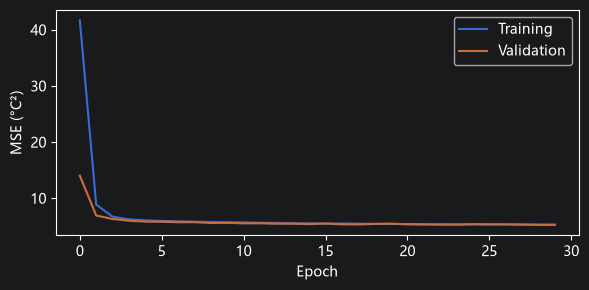

dense_temp Validation: {'samples': 8784, 'mae_c': 1.7624380377781592, 'rmse_c': 2.290138135749034, 'bias_c': -0.10010319130256846, 'parameters': 833, 'training_seconds': 16.184741400000348, 'best_epoch': 29}


In [7]:
def dataset(X, y=None, training=False):
    """Batches with bounded threading."""
    ds = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.threading.max_intra_op_parallelism = 1
    return ds.with_options(options).batch(64).prefetch(1)

records = {}
def train_model(name, multivariate=False, recurrent=False):
    """Train and save the best model."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    features = 4 if multivariate else 1
    layers = [keras.layers.Input((LOOKBACK, features))]
    layers += ([keras.layers.GRU(32)] if recurrent else
               [keras.layers.Flatten(), keras.layers.Dense(32, activation="relu")])
    model = keras.Sequential(layers + [keras.layers.Dense(1)])
    model.compile(optimizer=keras.optimizers.Adam(0.001), loss="mse", metrics=["mae"])
    train, val = splits["train"], splits["val"]
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(dataset(train["X"][:, :, :features], train["y"], True),
                        validation_data=dataset(val["X"][:, :, :features], val["y"]),
                        epochs=30, callbacks=[stop],shuffle=False, verbose=2)
    seconds = time.perf_counter() - start
    model.save(f"models/{name}.keras")
    pd.DataFrame(history.history).to_csv(f"outputs/history_{name}.csv", index=False)
    prediction = model.predict(dataset(val["X"][:, :, :features]), verbose=0).ravel()
    records[name] = {**metrics(val["y"], prediction), "parameters": model.count_params(),
                     "training_seconds": seconds, "best_epoch": int(np.argmin(history.history["val_loss"]) + 1)}
    pd.DataFrame(records).T.to_csv("outputs/validation_results.csv")
    plt.figure(figsize=(6, 3))
    plt.plot(history.history["loss"], label="Training")
    plt.plot(history.history["val_loss"], label="Validation")
    plt.xlabel("Epoch"); plt.ylabel("MSE (°C²)"); plt.legend()
    plt.tight_layout(); plt.savefig(f"figures/history_{name}.png"); plt.show()
    print(name, "Validation:", records[name])

train_model("dense_temp")

# 7. Temperature GRU

Use identical temperature inputs and training settings.

Epoch 1/30
820/820 - 3s - 4ms/step - loss: 34.4682 - mae: 4.1798 - val_loss: 13.3745 - val_mae: 2.8489
Epoch 2/30
820/820 - 3s - 3ms/step - loss: 12.3417 - mae: 2.7304 - val_loss: 10.6238 - val_mae: 2.5603
Epoch 3/30
820/820 - 3s - 3ms/step - loss: 10.4832 - mae: 2.5191 - val_loss: 9.1455 - val_mae: 2.3778
Epoch 4/30
820/820 - 3s - 3ms/step - loss: 8.5137 - mae: 2.2517 - val_loss: 7.2688 - val_mae: 2.0948
Epoch 5/30
820/820 - 3s - 3ms/step - loss: 6.9825 - mae: 2.0229 - val_loss: 6.4785 - val_mae: 1.9719
Epoch 6/30
820/820 - 3s - 3ms/step - loss: 6.4795 - mae: 1.9461 - val_loss: 6.1359 - val_mae: 1.9157
Epoch 7/30
820/820 - 3s - 3ms/step - loss: 6.2189 - mae: 1.9017 - val_loss: 6.1223 - val_mae: 1.9135
Epoch 8/30
820/820 - 3s - 3ms/step - loss: 5.9975 - mae: 1.8645 - val_loss: 5.8415 - val_mae: 1.8704
Epoch 9/30
820/820 - 3s - 4ms/step - loss: 5.8882 - mae: 1.8465 - val_loss: 5.7526 - val_mae: 1.8506
Epoch 10/30
820/820 - 3s - 4ms/step - loss: 5.7723 - mae: 1.8248 - val_loss: 5.5988 - 

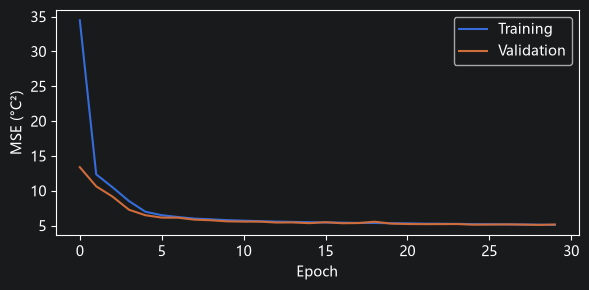

gru_temp Validation: {'samples': 8784, 'mae_c': 1.7371297902141347, 'rmse_c': 2.2561330313483614, 'bias_c': -0.15436724839432636, 'parameters': 3393, 'training_seconds': 85.2526781000006, 'best_epoch': 29}


In [9]:
train_model("gru_temp", recurrent=True)

# 8. Multivariate GRU

Add observed pressure, humidity and wind speed.

Epoch 1/30
820/820 - 4s - 4ms/step - loss: 33.6651 - mae: 4.0703 - val_loss: 11.5794 - val_mae: 2.6007
Epoch 2/30
820/820 - 3s - 3ms/step - loss: 9.3250 - mae: 2.3280 - val_loss: 7.3950 - val_mae: 2.0991
Epoch 3/30
820/820 - 3s - 3ms/step - loss: 6.8620 - mae: 2.0060 - val_loss: 6.3179 - val_mae: 1.9244
Epoch 4/30
820/820 - 3s - 3ms/step - loss: 6.0564 - mae: 1.8865 - val_loss: 5.8764 - val_mae: 1.8676
Epoch 5/30
820/820 - 3s - 3ms/step - loss: 5.6072 - mae: 1.8092 - val_loss: 5.4744 - val_mae: 1.7982
Epoch 6/30
820/820 - 3s - 3ms/step - loss: 5.3179 - mae: 1.7596 - val_loss: 5.2491 - val_mae: 1.7662
Epoch 7/30
820/820 - 3s - 3ms/step - loss: 5.1123 - mae: 1.7226 - val_loss: 5.1310 - val_mae: 1.7276
Epoch 8/30
820/820 - 3s - 3ms/step - loss: 4.9340 - mae: 1.6902 - val_loss: 5.0363 - val_mae: 1.7080
Epoch 9/30
820/820 - 3s - 4ms/step - loss: 4.7907 - mae: 1.6623 - val_loss: 4.8211 - val_mae: 1.6710
Epoch 10/30
820/820 - 3s - 3ms/step - loss: 4.6816 - mae: 1.6396 - val_loss: 4.8549 - val

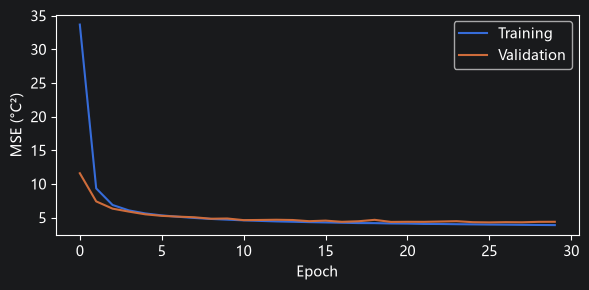

gru_multi Validation: {'samples': 8784, 'mae_c': 1.5716633030710885, 'rmse_c': 2.0678477085173266, 'bias_c': 0.10422867596533679, 'parameters': 3681, 'training_seconds': 84.78286759999992, 'best_epoch': 26}


In [10]:
train_model("gru_multi", multivariate=True, recurrent=True)

# 9. Multivariate Dense control

Use the same temperature, pressure, humidity and wind-speed inputs as multivariate GRU: `24×4 -> Flatten -> Dense(32, ReLU) -> Dense(1)`. Keep the same splits, training-period normalization, seed and early-stopping rules.

| Model | Temperature only | Four variables |
| --- | --- | --- |
| Dense | `dense_temp` | `dense_multi` |
| GRU | `gru_temp` | `gru_multi` |

This control checks whether added variables also help Dense, and how GRU compares with Dense using the same four inputs. Evaluation determines the outcome; parameter counts still differ.

This is a fixed extension after the original three-model evaluation, without tuning from the new test scores.

Epoch 1/30
820/820 - 1s - 1ms/step - loss: 27.4823 - mae: 3.8192 - val_loss: 9.7080 - val_mae: 2.4479
Epoch 2/30
820/820 - 1s - 621us/step - loss: 9.0550 - mae: 2.3471 - val_loss: 7.6518 - val_mae: 2.1767
Epoch 3/30
820/820 - 1s - 646us/step - loss: 7.0521 - mae: 2.0563 - val_loss: 6.5617 - val_mae: 2.0054
Epoch 4/30
820/820 - 1s - 666us/step - loss: 5.8078 - mae: 1.8468 - val_loss: 5.7637 - val_mae: 1.8676
Epoch 5/30
820/820 - 1s - 615us/step - loss: 5.2396 - mae: 1.7437 - val_loss: 5.2356 - val_mae: 1.7710
Epoch 6/30
820/820 - 1s - 616us/step - loss: 4.9810 - mae: 1.6976 - val_loss: 5.1043 - val_mae: 1.7485
Epoch 7/30
820/820 - 1s - 628us/step - loss: 4.8385 - mae: 1.6699 - val_loss: 4.9802 - val_mae: 1.7117
Epoch 8/30
820/820 - 1s - 671us/step - loss: 4.7422 - mae: 1.6508 - val_loss: 4.9952 - val_mae: 1.7156
Epoch 9/30
820/820 - 1s - 647us/step - loss: 4.6736 - mae: 1.6369 - val_loss: 4.8938 - val_mae: 1.6974
Epoch 10/30
820/820 - 1s - 621us/step - loss: 4.6112 - mae: 1.6249 - val_l

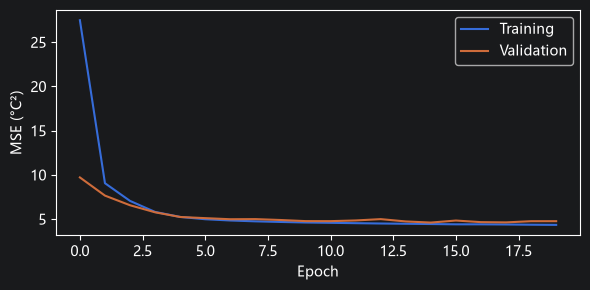

dense_multi Validation: {'samples': 8784, 'mae_c': 1.644507006890707, 'rmse_c': 2.145541517062073, 'bias_c': 0.02918657154554776, 'parameters': 3137, 'training_seconds': 11.032724400000006, 'best_epoch': 15}


In [11]:
# Use the same training helper with four input variables.
train_model("dense_multi", multivariate=True)

# 10. Shared test evaluation
Evaluate identical 2025 targets after fixing the plan; do not select further settings from test scores.
Shared evaluation includes persistence and all four learned models.

In [12]:
test = splits["test"]
predictions = pd.DataFrame({"target_time": test["times"], "observed_c": test["y"],
                            "persistence": test["latest"]})
for name in records:
    model = keras.saving.load_model(f"models/{name}.keras", compile=False)
    count = model.input_shape[-1]
    predictions[name] = model.predict(dataset(test["X"][:, :, :count]), verbose=0).ravel()
rows = []
for name in ["persistence"] + list(records):
    record = records.get(name, {"parameters": 0, "training_seconds": 0})
    rows.append({"model": name, **metrics(predictions.observed_c, predictions[name]),
                 "parameters": record["parameters"], "training_seconds": record["training_seconds"]})
results = pd.DataFrame(rows).set_index("model")
predictions.to_csv("outputs/test_predictions.csv", index=False)
results.to_csv("outputs/test_results.csv")
display(results)

,samples,mae_c,rmse_c,bias_c,parameters,training_seconds
model,,,,,,
persistence,8760,3.560174,4.680442,-0.002009,0,0.000000
dense_temp,8760,1.792809,2.332945,0.016207,833,16.184741
gru_multi,8760,1.604429,2.090741,0.248562,3681,84.782868
gru_temp,8760,1.770988,2.307551,-0.048988,3393,85.252678
dense_multi,8760,1.663471,2.152831,0.108781,3137,11.032724


# 11. Error analysis and paired intervals
Groups are post-test diagnostics; daily intervals exclude retraining uncertainty.

Retain the original three intervals and add paired MAE-difference intervals for multivariate Dense versus temperature Dense, and multivariate GRU versus multivariate Dense. Daily intervals describe test-date uncertainty for frozen models and exclude retraining variability.

Observed-target temperature bands are post-test diagnostics. A larger warm-group gain is an observation from this run; between-group significance and causal weather mechanisms have not been tested.

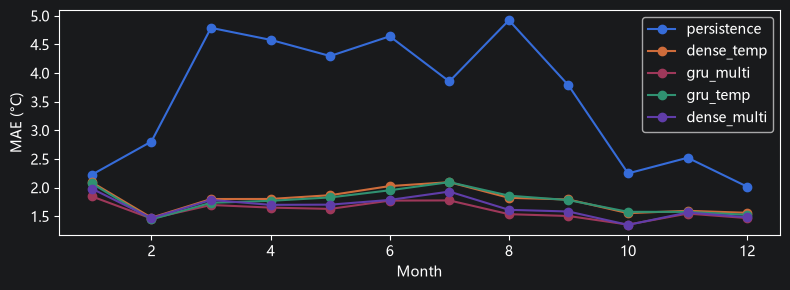

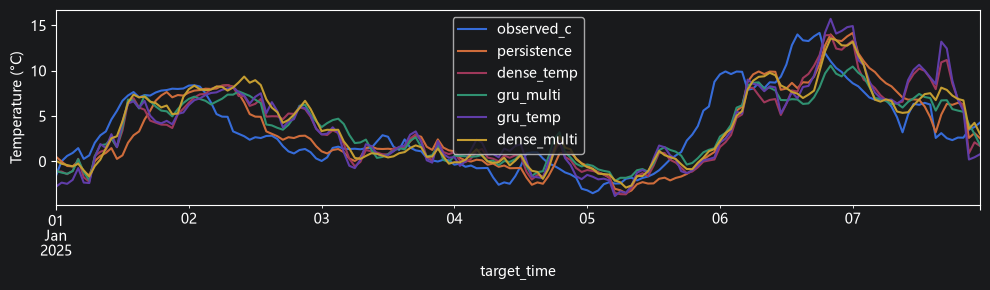

,samples,persistence,dense_temp,gru_multi,gru_temp,dense_multi
observed_c,,,,,,
<0°C,891,2.444568,1.706584,1.635926,1.671644,1.636507
0-<10°C,3259,2.834925,1.675097,1.537961,1.641128,1.590473
10-<20°C,3564,3.873460,1.751995,1.561786,1.723034,1.611432
≥20°C,1046,5.702658,2.372077,1.929991,2.423602,2.091190


,candidate,reference,mae_difference_c,reduction_pct,ci_low_c,ci_high_c
0,gru_temp,dense_temp,-0.021822,1.217170,-0.044434,0.000153
1,gru_multi,gru_temp,-0.166558,9.404837,-0.214215,-0.113192
2,gru_multi,persistence,-1.955744,54.933961,-2.155693,-1.771831
3,dense_multi,dense_temp,-0.129338,7.214266,-0.171656,-0.086688
4,gru_multi,dense_multi,-0.059042,3.549326,-0.092662,-0.026135


Temperature GRU vs Temperature Dense: MAE difference = -0.0218°C; MAE reduction = +1.22%; 95% daily CI = [-0.0444, +0.0002]°C; Interval includes zero
Multivariate GRU vs Temperature GRU: MAE difference = -0.1666°C; MAE reduction = +9.40%; 95% daily CI = [-0.2142, -0.1132]°C; Interval excludes zero
Multivariate GRU vs Persistence: MAE difference = -1.9557°C; MAE reduction = +54.93%; 95% daily CI = [-2.1557, -1.7718]°C; Interval excludes zero
Multivariate Dense vs Temperature Dense: MAE difference = -0.1293°C; MAE reduction = +7.21%; 95% daily CI = [-0.1717, -0.0867]°C; Interval excludes zero
Multivariate GRU vs Multivariate Dense: MAE difference = -0.0590°C; MAE reduction = +3.55%; 95% daily CI = [-0.0927, -0.0261]°C; Interval excludes zero
Observed temperature ≥20°C: N = 1046, Temperature GRU MAE = 2.424°C, Multivariate GRU MAE = 1.930°C, MAE reduction = 20.4%; Overall reduction = 9.4%.


In [13]:
names = ["persistence"] + list(records)
errors = predictions[names].astype(float).sub(predictions.observed_c.astype(float), axis=0)
absolute = errors.abs()
absolute.index = pd.DatetimeIndex(predictions.target_time)

monthly = absolute.groupby(absolute.index.month).mean()
monthly.to_csv("outputs/monthly_mae.csv")

bands = pd.cut(
    predictions.observed_c,
    [-np.inf, 0, 10, 20, np.inf],
    right=False,
    labels=["<0°C", "0-<10°C", "10-<20°C", "≥20°C"]
)
band_errors = absolute.reset_index(drop=True).groupby(bands, observed=False).mean()
band_errors.insert(0, "samples", bands.value_counts(sort=False))
band_errors.to_csv("outputs/temperature_band_mae.csv")

worst = []
for name in names:
    part = predictions.loc[
        errors[name].abs().nlargest(10).index,
        ["target_time", "observed_c", name]
    ].copy()
    part["model"] = name
    part = part.rename(columns={name: "predicted_c"})
    part["error_c"] = part.predicted_c - part.observed_c
    worst.append(part)
pd.concat(worst).to_csv("outputs/worst_errors.csv", index=False)

monthly.plot(marker="o", ylabel="MAE (°C)", xlabel="Month", figsize=(8, 3))
plt.tight_layout()
plt.savefig("figures/monthly_mae.png")
plt.show()

predictions.set_index("target_time").iloc[:168].plot(
    figsize=(10, 3), ylabel="Temperature (°C)"
)
plt.tight_layout()
plt.savefig("figures/prediction_trace.png")
plt.show()

display(band_errors)

# Resample complete days, weighted by sampled observation counts.
days = absolute.index.normalize()
sums = absolute.groupby(days).sum()
counts = absolute.groupby(days).size().to_numpy()
draws = np.random.default_rng(SEED).integers(
    0, len(counts), size=(2000, len(counts))
)

comparisons = []

# Two new comparisons complete the architecture/input controls.
pairs = [
    ("gru_temp", "dense_temp"),
    ("gru_multi", "gru_temp"),
    ("gru_multi", "persistence"),
    ("dense_multi", "dense_temp"),
    ("gru_multi", "dense_multi")
]

for candidate, reference in pairs:
    daily_difference = (sums[candidate] - sums[reference]).to_numpy()
    sampled = daily_difference[draws].sum(axis=1) / counts[draws].sum(axis=1)
    low, high = np.quantile(sampled, [0.025, 0.975])
    comparisons.append({
        "candidate": candidate,
        "reference": reference,
        "mae_difference_c": float(
            absolute[candidate].mean() - absolute[reference].mean()
        ),
        "reduction_pct": float(
            100 * (1 - absolute[candidate].mean() / absolute[reference].mean())
        ),
        "ci_low_c": float(low),
        "ci_high_c": float(high)
    })

comparison_results = pd.DataFrame(comparisons)
comparison_results.to_csv("outputs/paired_daily_bootstrap.csv", index=False)
display(comparison_results)

# Interpret the new controls without assuming improvement.
labels = {
    "dense_temp": "Temperature Dense",
    "dense_multi": "Multivariate Dense",
    "gru_temp": "Temperature GRU",
    "gru_multi": "Multivariate GRU",
    "persistence": "Persistence"
}

for row in comparison_results.itertuples():
    interval = (
        "Interval includes zero"
        if row.ci_low_c <= 0 <= row.ci_high_c
        else "Interval excludes zero"
    )
    print(
        f"{labels[row.candidate]} vs {labels[row.reference]}: "
        f"MAE difference = {row.mae_difference_c:+.4f}°C; "
        f"MAE reduction = {row.reduction_pct:+.2f}%; "
        f"95% daily CI = [{row.ci_low_c:+.4f}, {row.ci_high_c:+.4f}]°C; "
        f"{interval}"
    )

# Recompute warm-group and overall GRU gains.
warm = band_errors.loc["≥20°C"]
warm_gain = 100 * (1 - warm["gru_multi"] / warm["gru_temp"])
overall_gain = 100 * (
    1 - results.loc["gru_multi", "mae_c"] / results.loc["gru_temp", "mae_c"]
)

print(
    f"Observed temperature ≥20°C: N = {int(warm['samples'])}, "
    f"Temperature GRU MAE = {warm['gru_temp']:.3f}°C, "
    f"Multivariate GRU MAE = {warm['gru_multi']:.3f}°C, "
    f"MAE reduction = {warm_gain:.1f}%; "
    f"Overall reduction = {overall_gain:.1f}%."
)

# 12. Overall comparison and zoomed view

Use `results` from Step 10. The left panel shows all five methods with zero-based bars (0-4°C). The right panel uses zoomed dots (1.50-1.95°C) to show the MAE changes after adding variables to each architecture. Values and reductions come from this run.

Output: `figures/overall_mae_comparison.png`，3200×1800，16:9。

After completing the preceding steps, rerun this cell without retraining.

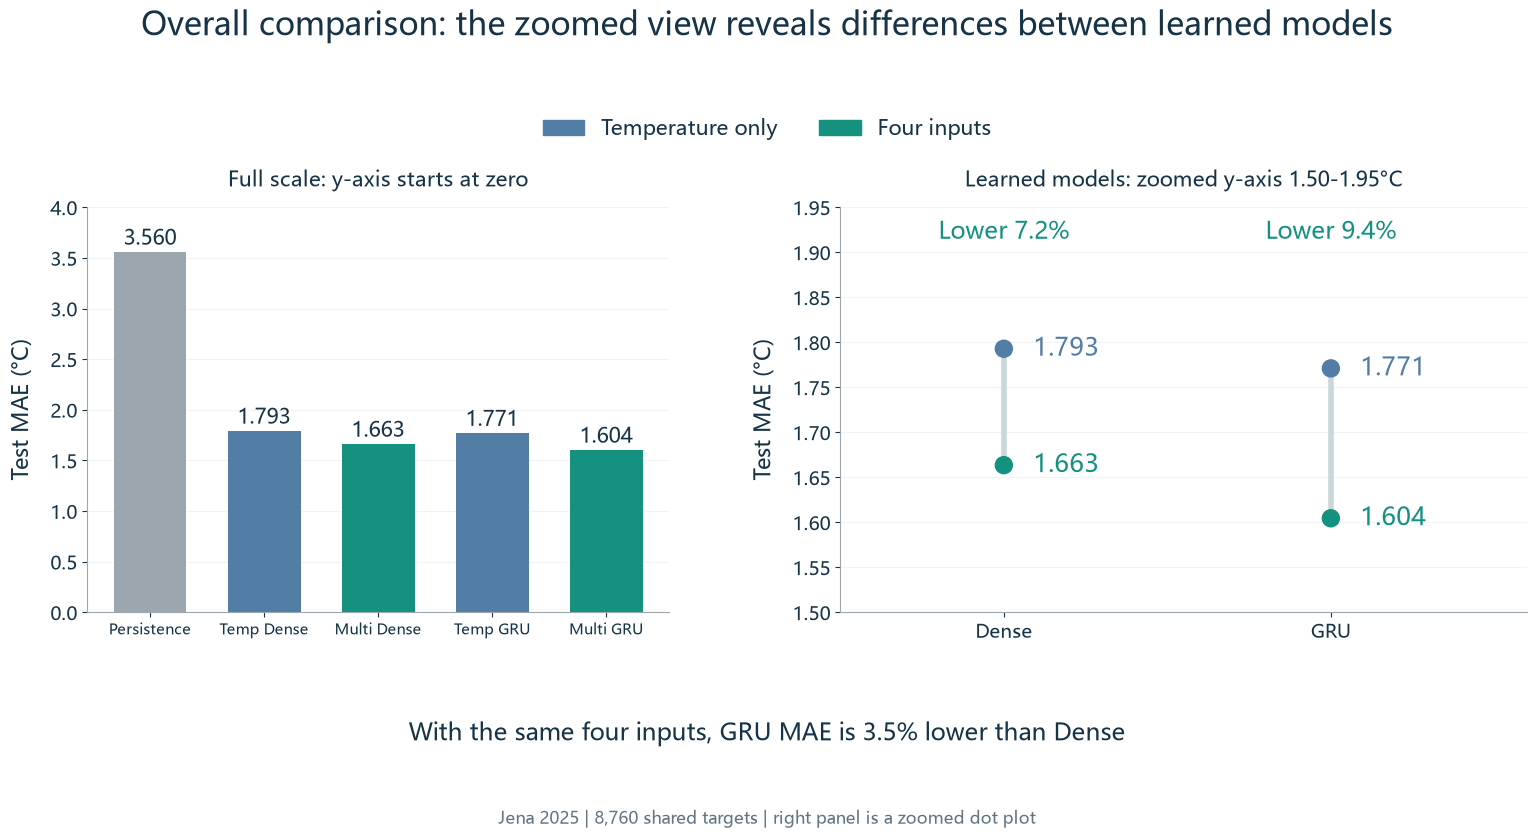

In [15]:
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Reuse test metrics, save and display the charts.
plt.rcParams.update({"font.size": 14})
INK, BLUE, GREEN, GREY = "#173447", "#527DA4", "#159180", "#9BA6AF"
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "text.color": INK,
    "legend.labelcolor": INK,
})

def style(ax, ylabel="Test MAE (°C)"):
    """Keep units visible on full-scale and zoomed axes."""
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E4E9EC", linewidth=0.8)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["bottom", "left"]:
        ax.spines[side].set_color("#9BA6AF")
    ax.tick_params(colors=INK, labelsize=14)
    ax.set_ylabel(ylabel, fontsize=16, color=INK, labelpad=12)


def save(fig, filename):
    """Export a high-resolution 16:9 image."""
    fig.savefig(Path("figures") / filename, dpi=200, facecolor="white")
    plt.show()
    plt.close(fig)


# Keep zero-based bars at left and a labeled zoomed dot plot at right.
models = ["persistence", "dense_temp", "dense_multi", "gru_temp", "gru_multi"]
values = results.loc[models, "mae_c"].to_numpy()

fig, (full, zoom) = plt.subplots(
    1, 2, figsize=(16, 9),
    gridspec_kw={"width_ratios": [1.0, 1.18]}
)
fig.subplots_adjust(left=.075, right=.975, top=.74, bottom=.29, wspace=.27)

fig.suptitle(
    "Overall comparison: the zoomed view reveals differences between learned models",
    fontsize=23, color=INK, y=.96
)
fig.legend(
    handles=[
        Patch(color=BLUE, label="Temperature only"),
        Patch(color=GREEN, label="Four inputs")
    ],
    loc="upper center",
    bbox_to_anchor=(.5, .86),
    ncol=2,
    frameon=False,
    fontsize=15
)

full.bar(
    np.arange(5), values, width=.64,
    color=[GREY, BLUE, GREEN, BLUE, GREEN]
)
full.set_xticks(
    np.arange(5),
    ["Persistence", "Temp Dense", "Multi Dense", "Temp GRU", "Multi GRU"],
    fontsize=11
)
full.set_ylim(0, 4.0)
full.set_yticks(np.arange(0, 4.01, .5))
full.set_title(
    "Full scale: y-axis starts at zero",
    fontsize=15, color=INK, pad=15
)
style(full)
full.tick_params(axis="x", labelsize=11)

for position, value in enumerate(values):
    full.text(
        position, value + .07, f"{value:.3f}",
        ha="center", fontsize=15, color=INK
    )

# Dot positions show MAE without exaggerating cropped bar lengths.
for position, architecture in enumerate(["dense", "gru"]):
    a = float(results.loc[f"{architecture}_temp", "mae_c"])
    b = float(results.loc[f"{architecture}_multi", "mae_c"])
    gain = 100 * (1 - b / a)

    zoom.plot(
        [position, position], [b, a],
        color="#CAD7DB", linewidth=4, zorder=2
    )
    zoom.scatter(
        [position, position], [a, b],
        color=[BLUE, GREEN], s=150, zorder=3
    )
    zoom.text(
        position + .09, a, f"{a:.3f}",
        color=BLUE, fontsize=18, va="center"
    )
    zoom.text(
        position + .09, b, f"{b:.3f}",
        color=GREEN, fontsize=18, va="center"
    )
    zoom.text(
        position, 1.915, f"Lower {gain:.1f}%",
        ha="center", fontsize=17, color=GREEN
    )

zoom.set_xticks([0, 1], ["Dense", "GRU"])
zoom.set_xlim(-.5, 1.6)
zoom.set_ylim(1.50, 1.95)
zoom.set_yticks(np.arange(1.50, 1.951, .05))
zoom.set_title(
    "Learned models: zoomed y-axis 1.50-1.95°C",
    fontsize=15, color=INK, pad=15
)
style(zoom)

architecture_gain = 100 * (
    1 - results.loc["gru_multi", "mae_c"]
    / results.loc["dense_multi", "mae_c"]
)
fig.text(
    .5, .155,
    f"With the same four inputs, GRU MAE is {architecture_gain:.1f}% lower than Dense",
    ha="center", va="center", fontsize=17, color=INK
)
fig.text(
    .5, .055,
    f"Jena 2025 | {int(results.loc['persistence', 'samples']):,} shared targets "
    "| right panel is a zoomed dot plot",
    ha="center", fontsize=12, color="#637581"
)

save(fig, "overall_mae_comparison.png")